## My first Python notebook

This notebook records the prompts, code, checks, and interpretations from Week 4.

In [ ]:
print("Hello, digital history!")

Hello, digital history!


In [ ]:
number_of_books = 500

In [ ]:
print(number_of_books)

500


In [9]:
## GOOGLE GEMINI GENERATED CODE
import pandas as pd

# 1. Load the CSV without changing it
df = pd.read_csv("book-sample.csv")

# 2. Print the number of rows and columns
print("=== 2. DATASET SHAPE ===")
rows, cols = df.shape
print(f"Total rows: {rows}")
print(f"Total columns: {cols}\n")

# 3. Display the first five rows
print("=== 3. FIRST FIVE ROWS ===")
# In Google Colab or Jupyter, display() renders a neat HTML table
display(df.head())
print("\n")

# 4. Print every column name and data type
print("=== 4. COLUMN NAMES AND DATA TYPES ===")
print(df.dtypes)
print("\n")

# 5. Print the number and percentage of missing values in every column
print("=== 5. MISSING VALUES ===")
missing_count = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_pct
})
print(missing_summary)
print("\n")

# 6. Calculate minimum, median, mean, and maximum of year_numeric
print("=== 6. YEAR NUMERIC STATISTICS ===")
if "year_numeric" in df.columns:
    yr = df["year_numeric"]
    print(f"Minimum year: {yr.min()}")
    print(f"Median year:  {yr.median()}")
    print(f"Mean year:    {yr.mean():.2f}")
    print(f"Maximum year: {yr.max()}")
else:
    print("Column 'year_numeric' not found.")
print("\n")

# 7. Count records by decade, country, language, and format (including missing)
print("=== 7. CATEGORICAL COUNTS (INCLUDING MISSING) ===")
target_columns = ["decade", "country", "language", "format"]
for col in target_columns:
    if col in df.columns:
        print(f"\n--- Counts for '{col}' ---")
        print(df[col].value_counts(dropna=False))
    else:
        print(f"\nColumn '{col}' not found.")
print("\n")

# 8. Check whether edition_id is unique
print("=== 8. EDITION ID UNIQUENESS CHECK ===")
if "edition_id" in df.columns:
    is_unique = df["edition_id"].is_unique
    print(f"Is 'edition_id' completely unique? {is_unique}")
    if not is_unique:
        print(f"Number of duplicate IDs: {df['edition_id'].duplicated().sum()}")
else:
    print("Column 'edition_id' not found.")

=== 2. DATASET SHAPE ===
Total rows: 500
Total columns: 11

=== 3. FIRST FIVE ROWS ===


,edition_id,short_title,author,printer,place,year,language,format,country,year_numeric,decade
0,627908,Das Newe Testament,NaN,Kunigunde Hergot,Nürnberg,1535,German,8o,Holy Roman Empire,1535,1530s
1,698366,Trewung vom liebebande oder hertztrewen. Item:...,"Streuber, Peter",Zacharias Bärwald,Leipzig,1590,German,8o,Holy Roman Empire,1590,1590s
2,691468,Romischer Keyserlicher Majestat ordnung und Re...,NaN,Johann Schöffer,Mainz,1530,German,2o,Holy Roman Empire,1530,1530s
3,708446,Zwo predigten vom gantzen Christlichen wesen u...,"Spangenberg, Cyriacus",Samuel Emmel,Strasbourg,1564,German,8o,Holy Roman Empire,1564,1560s
4,640867,"Corpus juris civilis, institutiones dn. Joachi...",NaN,Nikolaus II Episcopius,Basel,1555,Latin,2o,Swiss Confederation,1555,1550s




=== 4. COLUMN NAMES AND DATA TYPES ===
edition_id       int64
short_title     object
author          object
printer         object
place           object
year            object
language        object
format          object
country         object
year_numeric     int64
decade          object
dtype: object


=== 5. MISSING VALUES ===
              Missing Count  Missing Percentage (%)
edition_id                0                     0.0
short_title               0                     0.0
author                  100                    20.0
printer                   0                     0.0
place                     0                     0.0
year                      0                     0.0
language                 14                     2.8
format                   19                     3.8
country                   0                     0.0
year_numeric              0                     0.0
decade                    0                     0.0


=== 6. YEAR NUMERIC STATISTICS ===
Min

In [11]:
## GOOGLE GEMINI GENERATED CODE
import pandas as pd
import re

# Load the dataset
input_filename = "historic_photographs_sample_dataset.csv"
df = pd.read_csv(input_filename)

print(f"Input row count: {len(df)}")
print(f"Input column count: {len(df.columns)}")

# 1. Check unique record_id values
unique_ids = df['record_id'].nunique()
print(f"Unique record_id count: {unique_ids}")

# 2. Add place_trimmed (strip whitespace without standardization or translation)
df['place_trimmed'] = df['place_raw'].apply(
    lambda x: x.strip() if isinstance(x, str) else x
)

# 3. Define date parsing and certainty extraction function
def parse_date_fields(date_val):
    if pd.isna(date_val):
        return pd.Series([None, None, "unparsed"])

    s = str(date_val).strip()
    s_lower = s.lower()

    # Extract all 4-digit years
    years = re.findall(r'\b\d{4}\b', s)

    y_start = int(years[0]) if len(years) > 0 else None
    y_end = int(years[1]) if len(years) > 1 else y_start

    # Determine date_certainty using explicit precedence rules:
    # 1. "uncertain" if date_raw contains ?
    if '?' in s:
        certainty = "uncertain"
    # 2. "approximate" if it begins with c. after trimming and lowercasing
    elif s_lower.startswith('c.'):
        certainty = "approximate"
    # 3. "supplied/inferred" if it begins with [
    elif s.startswith('['):
        certainty = "supplied/inferred"
    # 4. "range" if it contains two four-digit years
    elif len(years) >= 2:
        certainty = "range"
    # 5. "exact" if it contains one four-digit year
    elif len(years) == 1:
        certainty = "exact"
    # 6. "unparsed" otherwise
    else:
        certainty = "unparsed"

    return pd.Series([y_start, y_end, certainty])

# Apply parsing and assign nullable integer types ('Int64') for years
parsed_dates = df['date_raw'].apply(parse_date_fields)
df['year_start'] = parsed_dates[0].astype('Int64')
df['year_end'] = parsed_dates[1].astype('Int64')
df['date_certainty'] = parsed_dates[2]

# 4. Print missing counts for newly created columns
print("\n=== Missing Values in New Columns ===")
new_cols = ['year_start', 'year_end', 'date_certainty', 'place_trimmed']
print(df[new_cols].isnull().sum())

# 5. Print a representative table showing date_raw and the three derived date columns
print("\n=== Representative Sample (10 Rows) ===")
print(df[['date_raw', 'year_start', 'year_end', 'date_certainty']].head(10).to_string(index=False))

# 6. Assertions to guarantee structural integrity
original_cols = [
    'record_id', 'title_raw', 'creator_raw', 'date_raw', 'place_raw',
    'country_raw', 'subject_raw', 'object_type_raw', 'caption_language_raw',
    'holding_institution_raw', 'rights_raw', 'box_folder_raw', 'filename_raw',
    'notes_raw', 'creator_authority_uri', 'place_wikidata_qid', 'lcsh_subjects'
]

assert len(df) == 100, f"Assertion failed: Expected 100 rows, got {len(df)}."
assert df['record_id'].is_unique, "Assertion failed: record_id values are not unique."
for col in original_cols:
    assert col in df.columns, f"Assertion failed: Original column '{col}' is missing."

print("\nAll structural assertions passed successfully!")

# 7. Save the record-level transformed table
output_record_file = "photographs_for_rawgraphs.csv"
df.to_csv(output_record_file, index=False, encoding="utf-8")
print(f"Saved record-level dataset to {output_record_file}")

# 8. Create aggregated DataFrame grouped by date_certainty
all_categories = ["exact", "range", "approximate", "uncertain", "supplied/inferred", "unparsed"]
agg_df = (
    df['date_certainty']
    .value_counts()
    .reindex(all_categories, fill_value=0)
    .reset_index()
)
agg_df.columns = ['date_certainty', 'record_count']

# 9. Print aggregated table and assert record count sum
print("\n=== Aggregated Date Certainty Counts ===")
print(agg_df.to_string(index=False))

assert agg_df['record_count'].sum() == 100, f"Assertion failed: record_count sum is {agg_df['record_count'].sum()}, expected 100."
print("Aggregation sum assertion passed successfully!")

# 10. Save aggregated table
output_agg_file = "date_certainty_counts_for_rawgraphs.csv"
agg_df.to_csv(output_agg_file, index=False, encoding="utf-8")
print(f"Saved aggregated dataset to {output_agg_file}")

Input row count: 100
Input column count: 17
Unique record_id count: 100

=== Missing Values in New Columns ===
year_start        1
year_end          1
date_certainty    0
place_trimmed     0
dtype: int64

=== Representative Sample (10 Rows) ===
   date_raw  year_start  year_end    date_certainty
  1930-1931        1930      1931             range
       1891        1891      1891             exact
      1896?        1896      1896         uncertain
  1892-1893        1892      1893             range
     [1924]        1924      1924 supplied/inferred
    c. 1935        1935      1935       approximate
  1898-1899        1898      1899             range
10 Feb 1933        1933      1933             exact
       1928        1928      1928             exact
  1926-1927        1926      1927             range

All structural assertions passed successfully!
Saved record-level dataset to photographs_for_rawgraphs.csv

=== Aggregated Date Certainty Counts ===
   date_certainty  record_count
 

=== AGGREGATED DECADE COUNTS ===
decade  record_count
 1500s            20
 1510s            33
 1520s            64
 1530s            50
 1540s            50
 1550s            67
 1560s            58
 1570s            54
 1580s            53
 1590s            47
 1600s             4


Assertion passed: Sum of counts equals total input rows.



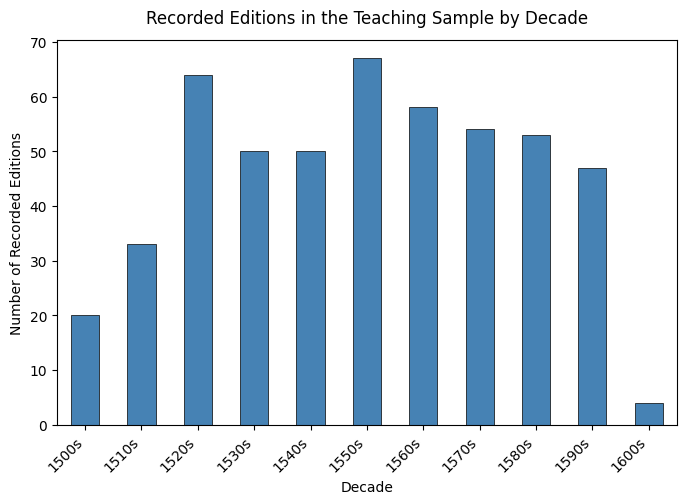

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the CSV without changing it
df = pd.read_csv("book-sample.csv")

# 2. Count rows by decade, keeping missing categories visible
decade_counts = df['decade'].value_counts(dropna=False)

# 3. Sort decade labels chronologically (handling NaN/missing cleanly)
decade_counts.index = decade_counts.index.fillna("Missing").astype(str)
decade_counts = decade_counts.sort_index()

# 4. Print the aggregated decade-and-count table before plotting
print("=== AGGREGATED DECADE COUNTS ===")
agg_table = decade_counts.reset_index()
agg_table.columns = ['decade', 'record_count']
print(agg_table.to_string(index=False))
print("\n")

# 5. Assert that the sum of all bar counts equals the number of input rows
assert agg_table['record_count'].sum() == len(df), "Assertion Error: Sum of counts does not match total rows."
print("Assertion passed: Sum of counts equals total input rows.\n")

# 6. Create the bar chart
fig, ax = plt.subplots(figsize=(8, 5))
decade_counts.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black', linewidth=0.5)

# 7. Format the chart with an honest title and zero-indexed axis
ax.set_title("Recorded Editions in the Teaching Sample by Decade", fontsize=12, pad=12)
ax.set_xlabel("Decade", fontsize=10)
ax.set_ylabel("Number of Recorded Editions", fontsize=10)
ax.set_ylim(bottom=0)
plt.xticks(rotation=45, ha='right')

# 8. Save at 300 dpi with a tight bounding box, then display
plt.savefig("book-records-by-decade.png", dpi=300, bbox_inches='tight')
plt.show()

=== AGGREGATED DECADE COUNTS ===
decade  record_count
 1500s            20
 1510s            33
 1520s            64
 1530s            50
 1540s            50
 1550s            67
 1560s            58
 1570s            54
 1580s            53
 1590s            47
 1600s             4


Assertion passed: Sum of counts equals total input rows.



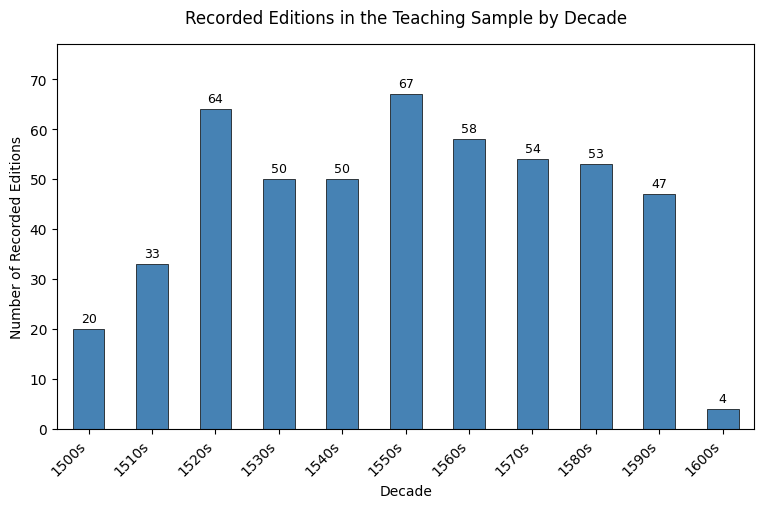

In [13]:
## GOOGLE GEMINI GENERATED CODE
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the CSV without changing it
df = pd.read_csv("book-sample.csv")

# 2. Count rows by decade, keeping missing categories visible
decade_counts = df['decade'].value_counts(dropna=False)

# 3. Sort decade labels chronologically (handling NaN/missing cleanly)
decade_counts.index = decade_counts.index.fillna("Missing").astype(str)
decade_counts = decade_counts.sort_index()

# 4. Print the aggregated decade-and-count table before plotting
print("=== AGGREGATED DECADE COUNTS ===")
agg_table = decade_counts.reset_index()
agg_table.columns = ['decade', 'record_count']
print(agg_table.to_string(index=False))
print("\n")

# 5. Assert that the sum of all bar counts equals the number of input rows
assert agg_table['record_count'].sum() == len(df), "Assertion Error: Sum of counts does not match total rows."
print("Assertion passed: Sum of counts equals total input rows.\n")

# 6. Create the bar chart
fig, ax = plt.subplots(figsize=(9, 5))
decade_counts.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black', linewidth=0.5)

# Display exact counts above each bar
ax.bar_label(ax.containers[0], padding=3, fontsize=9)

# 7. Format the chart with an honest title and zero-indexed axis
ax.set_title("Recorded Editions in the Teaching Sample by Decade", fontsize=12, pad=15)
ax.set_xlabel("Decade", fontsize=10)
ax.set_ylabel("Number of Recorded Editions", fontsize=10)

# Adjust Y-axis limit to accommodate the labels at the top of the tallest bars
max_count = decade_counts.max()
ax.set_ylim(bottom=0, top=max_count * 1.15)

plt.xticks(rotation=45, ha='right')

# 8. Save at 300 dpi with a tight bounding box, then display
plt.savefig("book-records-by-decade.png", dpi=300, bbox_inches='tight')
plt.show()